# Comparison of trained model architectures

## 1.import of data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("../results/eval_metrics.csv")
df = pd.read_csv("../results/eval_steps/quadrustand_spot_flat_baseline_2026-10-19_09-16-58.csv")
df['variant']
df.columns
df.head()


,variant,checkpoint,seed,num_envs,num_steps,lin_vel_error,yaw_error,tilt_mean,tilt_max,fall_rate,tracking_success
0,rsl_rl_cfg_entry_point,logs/rsl_rl/quadrustand_spot_flat_baseline/202...,1000,16,1000,0.669563,0.159485,0.037910,0.219410,0.0625,0.157072
1,rsl_rl_cfg_entry_point,logs/rsl_rl/quadrustand_spot_flat_baseline/202...,1000,16,1000,0.738458,0.125498,0.033780,0.183222,0.0000,0.122750
2,rsl_rl_cfg_entry_point,logs/rsl_rl/quadrustand_spot_flat_baseline/202...,1000,16,1000,0.416224,0.184563,0.041801,0.530637,0.0625,0.266829
3,rsl_rl_deep_1_cfg_entry_point,logs/rsl_rl/quadrustand_spot_flat_deep_1/2026-...,1000,16,1000,1.290817,0.224832,0.036342,0.329809,0.0000,0.000500
4,rsl_rl_deep_2_cfg_entry_point,logs/rsl_rl/quadrustand_spot_flat_deep_2/2026-...,1000,16,1000,0.928001,0.115495,0.034363,0.227039,0.0000,0.056625


In [7]:
df['variant'].unique

<bound method Series.unique of 0                rsl_rl_cfg_entry_point
1                rsl_rl_cfg_entry_point
2                rsl_rl_cfg_entry_point
3         rsl_rl_deep_1_cfg_entry_point
4         rsl_rl_deep_2_cfg_entry_point
5         rsl_rl_deep_5_cfg_entry_point
6    rsl_rl_extra_small_cfg_entry_point
7          rsl_rl_large_cfg_entry_point
8         rsl_rl_medium_cfg_entry_point
9          rsl_rl_small_cfg_entry_point
Name: variant, dtype: str>

In [15]:
target_variant = "rsl_rl_cfg_entry_point"
df_var = df[df['variant'] == target_variant]
df_var['num_steps'].shape
mean_lin_error = df_var['lin_vel_error']
mean_lin_error.shape

(3,)

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(df_var['num_steps'][0],)


In [28]:
df1 = pd.read_csv("../results/eval_steps/quadrustand_spot_flat_baseline_2026-10-19_09-16-58.csv")
df1.head()

names = [
    "quadrustand_spot_flat_extra_sm",
    "quadrustand_spot_flat_deep_2_2",
    "quadrustand_spot_flat_medium_",
    "quadrustand_spot_flat_baseline_",
    "quadrustand_spot_flat_deep_1_2",
    "quadrustand_spot_flat_large_202",
    "quadrustand_spot_flat_deep_5_2",
    "quadrustand_spot_flat_baseline_",
    "quadrustand_spot_flat_baseline_",
    "quadrustand_spot_flat_small_202",
]

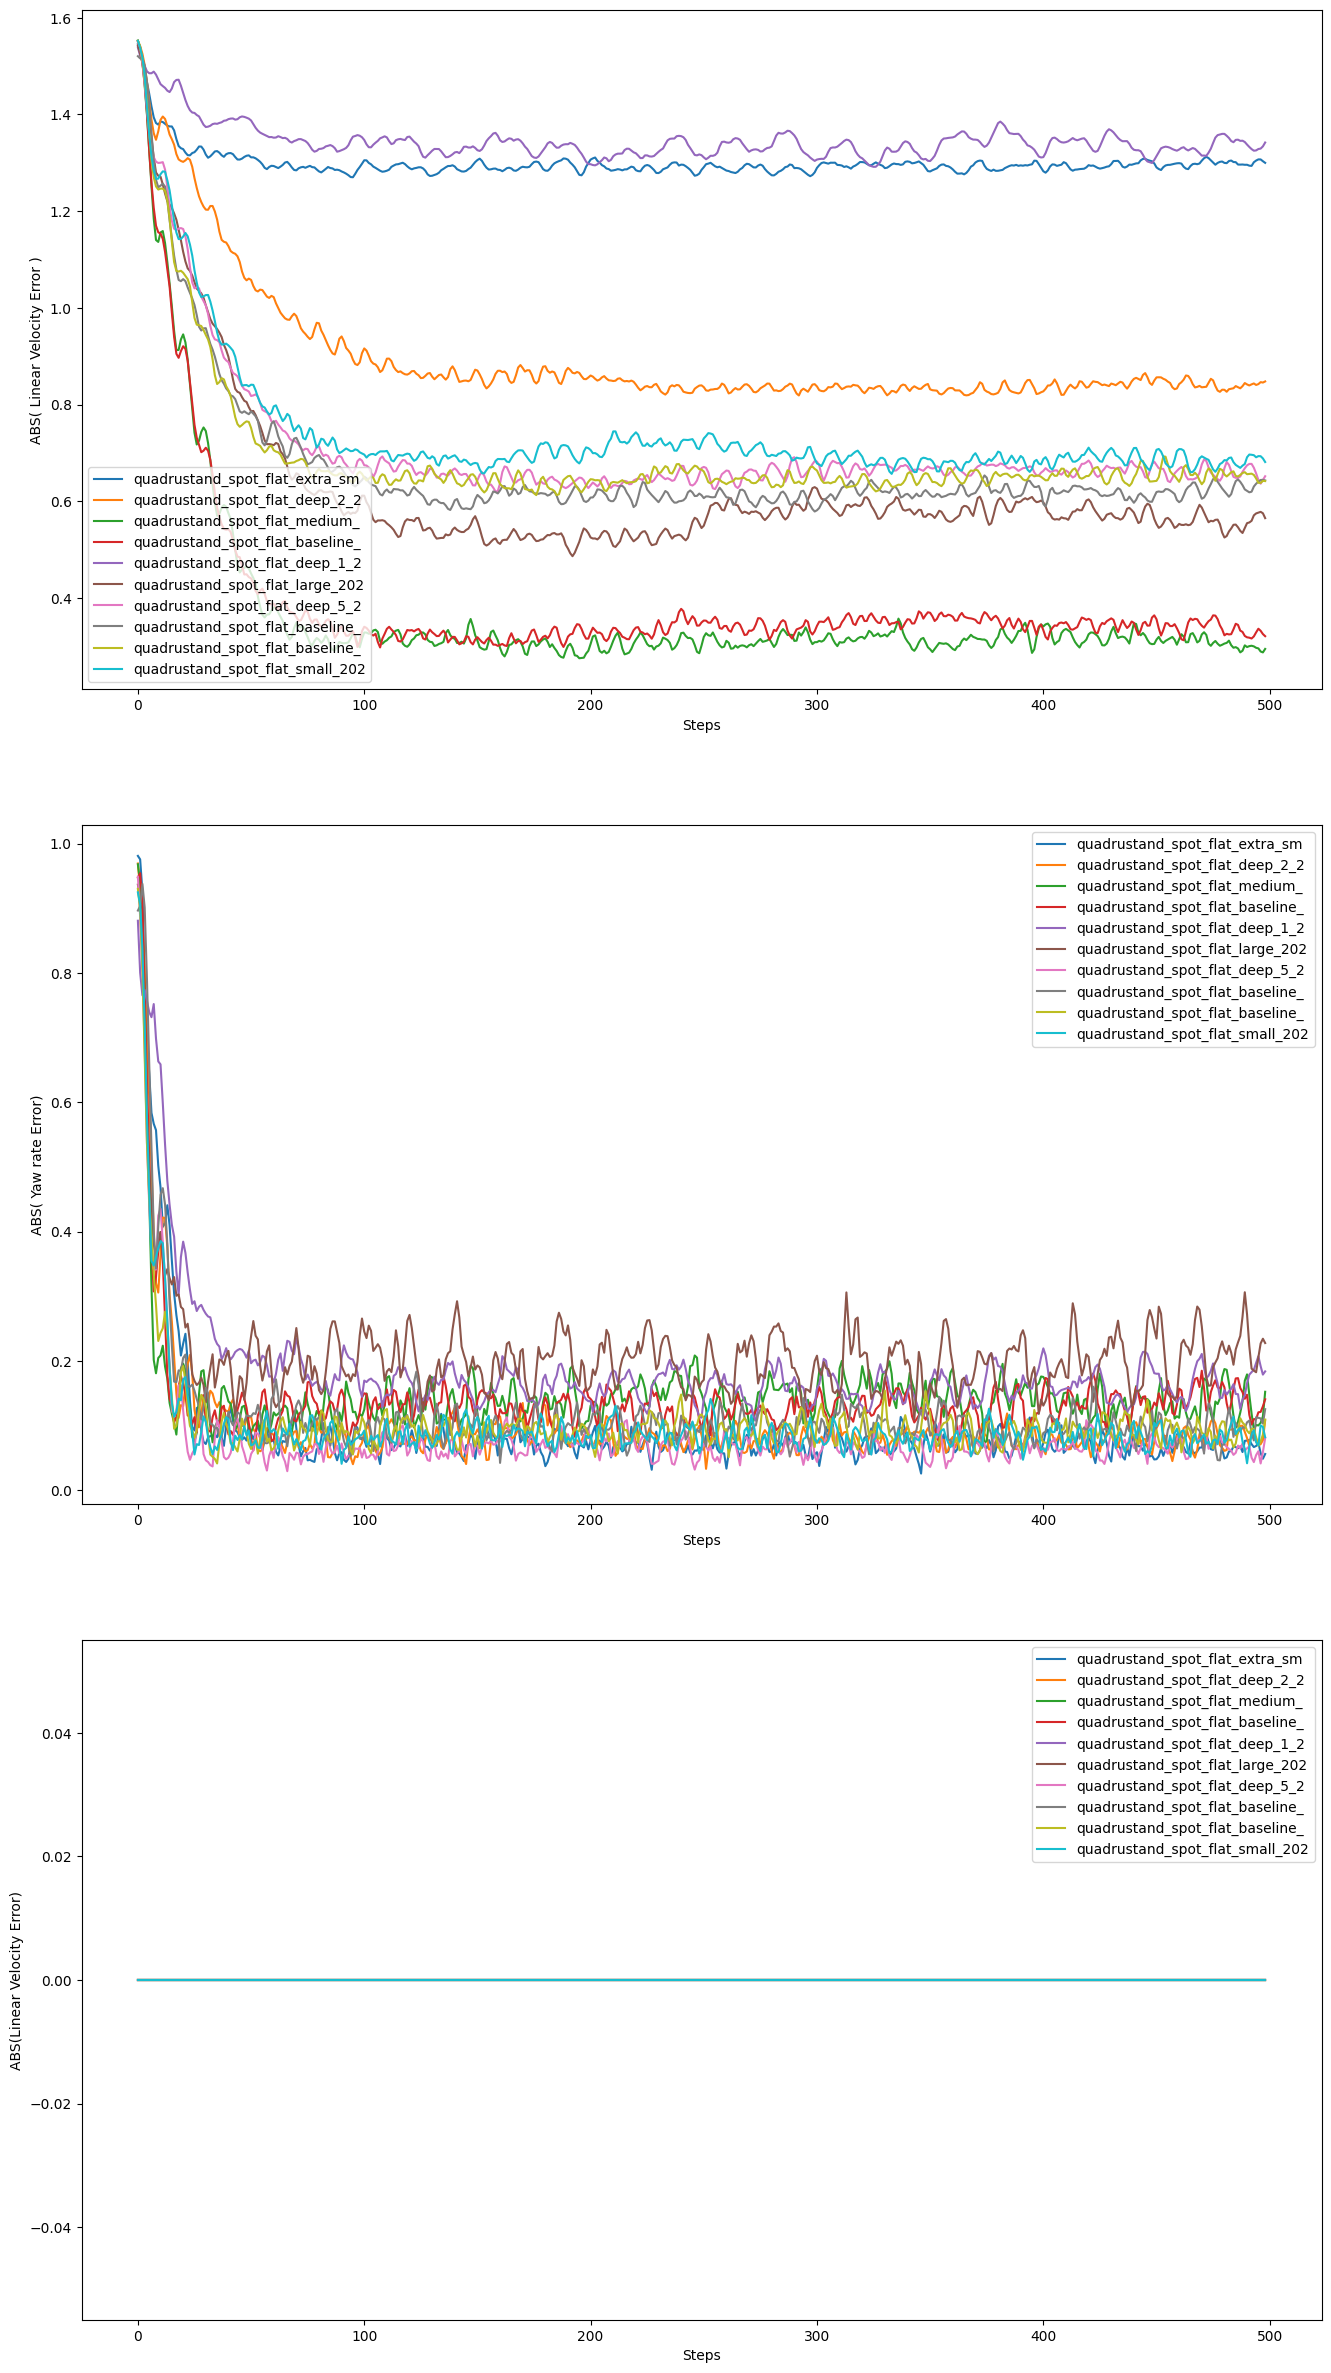

In [67]:
import glob
import pandas as pd
import numpy as np


Succes_rate =[]

file_list = glob.glob("../results/eval_steps/*.csv")
plt.figure(figsize=(16, 30))


for file in file_list:
    df = pd.read_csv(file)
    plt.subplot(3,1,1)
    plt.plot(df['lin_vel_error'][0:-501])
    plt.xlabel("Steps")
    plt.ylabel("ABS( Linear Velocity Error )")
    plt.legend(names).set_loc("lower left")
    plt.subplot(3,1,2)
    plt.plot(df['yaw_error'][0:-501]) #*(180/3.14)
    plt.xlabel("Steps")
    plt.ylabel("ABS( Yaw rate Error)")
    plt.legend(names).borderpad
    plt.subplot(3,1,3)
    plt.plot(df['fall_rate'][0:-501])
    plt.legend(names)
    plt.xlabel("Steps")
    plt.ylabel("ABS(Linear Velocity Error)")


    

#################quadrustand_spot_flat_extra_sm#################
--------------          13.477656058967113 -------   
#################quadrustand_spot_flat_deep_2_2#################
--------------          9.060516096651554 -------   
#################quadrustand_spot_flat_medium_#################
--------------          3.911558799445629 -------   
#################quadrustand_spot_flat_baseline_#################
--------------          4.236873760819435 -------   
#################quadrustand_spot_flat_deep_1_2#################
--------------          14.121338725090027 -------   
#################quadrustand_spot_flat_large_202#################
--------------          6.52741052210331 -------   
#################quadrustand_spot_flat_deep_5_2#################
--------------          7.751580588519573 -------   
#################quadrustand_spot_flat_baseline_#################
--------------          6.8710170313715935 -------   
#################quadrustand_spot_flat_baseline_####

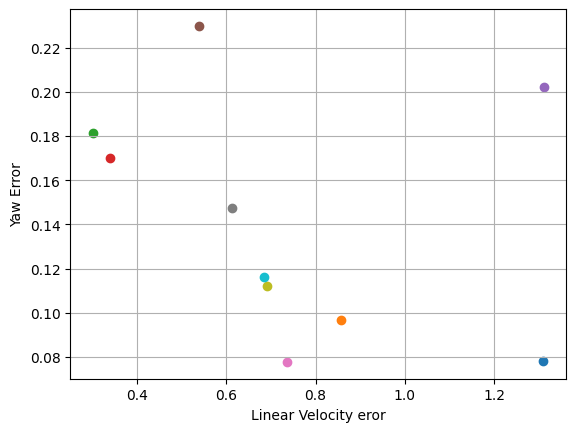

In [91]:

sucess_list =[]
linVelError_list =[]
plt.figurefigsize=(16, 16)

for i,file in enumerate(file_list):
    df = pd.read_csv(file)

    short_name = names[i]
    

    linVelError = df['lin_vel_error'].median()
    yawError = df['yaw_error'].median()
    fallrate = df['fall_rate'].median()
    plt.scatter(linVelError,yawError)
    plt.xlabel("Linear Velocity eror")
    plt.ylabel("Yaw Error")
    Succes_number =  (10 * linVelError + 5 * yawError)
    sucess_list.append(Succes_number)
    print(f"#################{short_name}#################")
    print(f"--------------          {Succes_number} -------   ")
plt.grid()
#plt.legend(names)
succes_dict = dict(zip(names, sucess_list))
sorted_succes_dict = dict(
    sorted(succes_dict.items(), key=lambda item: item[1])
)

print(sorted_succes_dict)

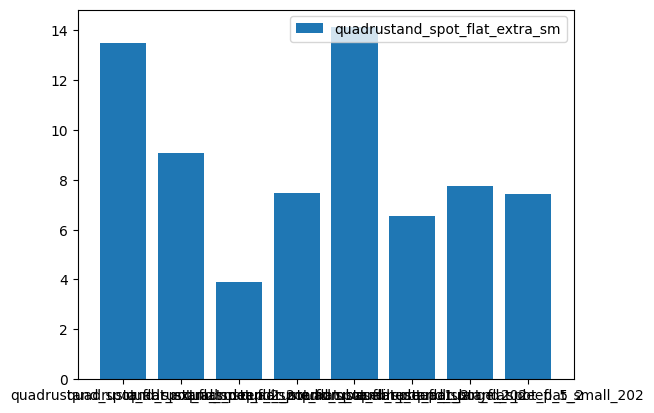

In [93]:
plt.figurefigsize=(16, 16)
plt.bar(names,sucess_list)
plt.legend(names)